**Task 3**

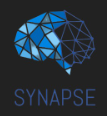

# Unsupervised Learning: Clustering, Dimensionality Reduction, and Association Rules

Unsupervised learning can be broken down into three main tasks:

- **Clustering**  
- **Dimensionality Reduction**  
- **Association Rules**  

Let's explore these topics :))  

Clustering is an unsupervised learning technique used to group similar data points together. It's widely used in applications like customer segmentation, anomaly detection, and more. In this task, we'll explore different clustering algorithms and visualize their results.  

Dimensionality reduction is a technique used to reduce the number of features in a dataset while retaining most of the important information. This helps in better visualization, faster computation, and noise reduction.  

Association rules are used to discover interesting relationships between variables in large datasets. A common example is market basket analysis, where we find products that are frequently bought together.  

In this task, we'll work with the **Online Retail dataset**, which contains transactional data from an e-commerce retailer. We'll use this dataset to:

- Cluster customers based on their purchasing behavior.  
- Reduce feature dimensions for visualization using PCA.  
- Discover associations between products using association rule mining.  


In [1]:
# Basic Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# For clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
# For association rules
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
# For interactive widgets
from ipywidgets import interact
# Misc
import warnings
warnings.filterwarnings("ignore")

Use the Dataset provided "Online_Retail.csv"

Mount the drive

In [2]:
import pandas as pd

from google.colab import drive

drive.mount('/content/drive')
# Load the dataset
df = pd.read_csv("/content/drive/MyDrive/OnlineRetail.csv", encoding='latin1') #Add the path in the ""

Mounted at /content/drive


Understanding the data

In [3]:
# print 1st few rows of the dataset, its shape and the columns
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  
(541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   

In [4]:
# check for null values
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Analyse the Missing Values

What are some meaningfull conclusions you can derive from them?

# Answer:
Since, 1454 is a very small fraction of the total rows of the dataset we can drop it. Here since we are doing customer level analysis, we have to drop the rows with null values.

From the previous output, we observe:
- `Description` has **1454 missing values** — this is a small amount compared to the total rows. Since association rules require product names, we will **drop rows with missing `Description`**.
- `CustomerID` has **135080 missing values**, which is a large amount. Whether to keep or drop these rows depends on our analysis:
  - If we want to do **customer-level analysis or clustering**, we must have `CustomerID`. In that case, we will **drop rows where `CustomerID` is missing**.
  - If we only want **product-level analysis** (e.g., frequent items), we can keep them.
  
In this task, we will proceed with **customer-level analysis**, so we will **drop rows where `CustomerID` is missing**.

In [5]:
#Drop the rows with missing\null values
df = df.dropna(subset=['Description', 'CustomerID'])
df.shape
#Re-check the shape and missing values

(406829, 8)

In [6]:
# Remove rows with negative or zero Quantity
df = df[df['Quantity']>0]
print(df.shape)
# Remove rows with zero or negative UnitPrice
df = df[df['UnitPrice']>0]
print(df.shape)
# Remove cancelled invoices (those starting with 'C')
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
print(df.shape)

(397924, 8)
(397884, 8)
(397884, 8)


In [7]:
# Verify there are no negative values left
print(df['Quantity'].min())
print(df['UnitPrice'].min())
# Quick summary after cleaning
df.describe()

1
0.001


,Quantity,UnitPrice,CustomerID
count,397884.000000,397884.000000,397884.000000
mean,12.988238,3.116488,15294.423453
std,179.331775,22.097877,1713.141560
min,1.000000,0.001000,12346.000000
25%,2.000000,1.250000,13969.000000
50%,6.000000,1.950000,15159.000000
75%,12.000000,3.750000,16795.000000
max,80995.000000,8142.750000,18287.000000


In [8]:
# Check how many duplicate rows exist
df.duplicated().sum()

np.int64(5192)

In [9]:
# Drop duplicate rows
df = df.drop_duplicates()
# Verify again
df.duplicated().sum()

np.int64(0)

Country
United Kingdom    349203
Germany             9025
France              8326
EIRE                7226
Spain               2479
Netherlands         2359
Belgium             2031
Switzerland         1841
Portugal            1453
Australia           1181
Name: count, dtype: int64


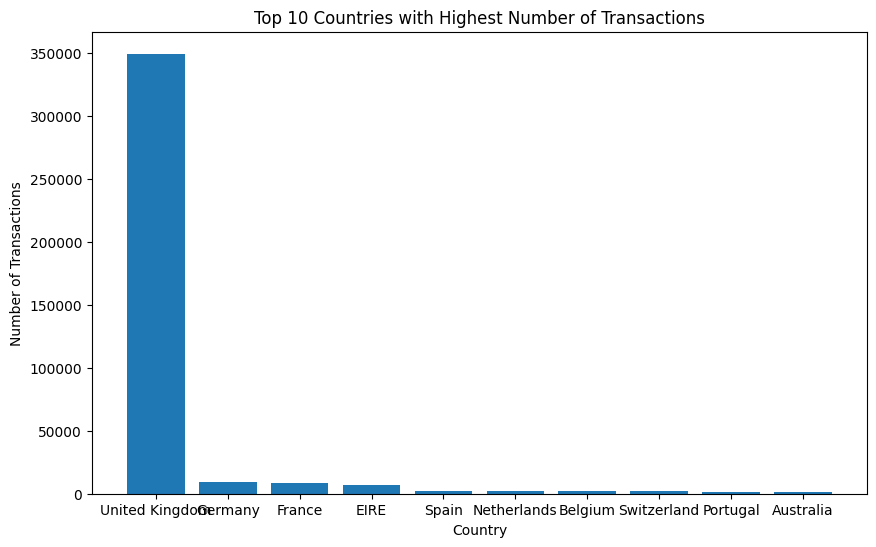

In [10]:
# Identify the top 10 countries with the highest number of transactions
top_countries = df['Country'].value_counts().head(10)
print(top_countries)
# Hint: Use a **horizontal bar chart** to visualize the results.
plt.figure(figsize=(10,6))
plt.bar(top_countries.index, top_countries.values)
plt.xlabel('Country')
plt.ylabel('Number of Transactions')
plt.title('Top 10 Countries with Highest Number of Transactions')
plt.show()

Pre-Processing the data for PCA and clustering

In [11]:
#Create a new TotalAmount column(Quantity * Unit price)
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']
# Aggregate numeric data at the customer level
# customer_df = df.groupby('CustomerID').agg({
#     'Quantity': 'sum',
#     'TotalAmount': 'sum'
# }).reset_index()

customer_df = df.groupby('CustomerID').agg({
    'Quantity': 'sum',
    'TotalAmount': 'sum'
}).reset_index()
customer_df.shape
# Keep only numeric columns for PCA

(4338, 3)

In [12]:
#Standardize the numeric features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
customer_df = scaler.fit_transform(customer_df[['Quantity', 'TotalAmount']])

Now that you have understood how to preprocess data for PCA through Online Retail dataset, we will apply similar steps to a new dataset: the Customer dataset.

This will help reinforce your understanding of dimensionality reduction and Clustering, while working with a dataset that is easier to visualize in 2D and 3D.

From this point onward, we will use the Customer_Data dataset provided

In [13]:
# Load the dataset

df_2= pd.read_csv("/content/drive/MyDrive/Customer_Data.csv") # Continue with the routine
print(df_2.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUSTID                            8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [14]:
#Check for missing values
df_2.isnull().sum()

,0
CUSTID,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0


In [15]:
#Drop CUST_ID (identifier, not useful for PCA)
df_2 = df_2.drop(columns=['CUSTID'])

In [16]:
#Handle missing values if needed
df_2 = df_2.fillna(df_2.median(numeric_only=True))
# Option: fill missing values with median (common in financial datasets)

Explain
Why did we fill the missing values in this dataset instead of dropping them, like we did in the previous dataset?

Answer:
Because here they are feature values and in the previous dataset they were customer identity values. Here, dropping can lead to loss of many valid observations.

In [17]:
#Standardize numeric features
scaler = StandardScaler()
df_2 = scaler.fit_transform(df_2)

In [18]:
#Verify scaled data
print(df_2.shape)
print(df_2[:5])

(8950, 17)
[[-0.73198937 -0.24943448 -0.42489974 -0.35693402 -0.34907882 -0.46678555
  -0.80649035 -0.67866081 -0.70731317 -0.67534886 -0.47606982 -0.51133325
  -0.9603784  -0.52897879 -0.3024     -0.52555097  0.36067954]
 [ 0.78696085  0.13432467 -0.46955188 -0.35693402 -0.45457623  2.60560451
  -1.22175806 -0.67866081 -0.91699519  0.57396272  0.11007385 -0.59179588
   0.68867844  0.81864213  0.09749953  0.2342269   0.36067954]
 [ 0.44713513  0.51808382 -0.10766823  0.10888851 -0.45457623 -0.46678555
   1.26984323  2.67345108 -0.91699519 -0.67534886 -0.47606982 -0.10902012
   0.82609984 -0.38380474 -0.0932934  -0.52555097  0.36067954]
 [ 0.04909914 -1.01695278  0.23205785  0.54618946 -0.45457623 -0.36865325
  -1.01412545 -0.39931927 -0.91699519 -0.25891333 -0.3295339  -0.55156456
   0.82609984 -0.59868826 -0.2283069  -0.52555097  0.36067954]
 [-0.3587753   0.51808382 -0.46206305 -0.34729428 -0.45457623 -0.46678555
  -1.01412545 -0.39931927 -0.91699519 -0.67534886 -0.47606982 -0.551564

# Dimensionality Reduction using PCA - Principal Component Analysis

Ref.: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

Theory: https://towardsdatascience.com/the-mathematics-behind-principal-component-analysis-fff2d7f4b643

Theory: https://www.youtube.com/watch?v=FgakZw6K1QQ

Implementation: https://youtu.be/OFyyWcw2cyM (Jump to timestamp - 13:50 for PCA implementaion)

Before we start of with this, **explain what PCA is and why is it necessary?**

Answer:
So, PCA stands for Principal Component Analysis. It is used to reduce the dimensions while preserving the important variation

Reduce the number of dimensions using PCA,

Hints:
1. Initialise instance of PCA and set *n_components* to 0.9 and *random_state* to 20.
2. Fit X_scaled over the PCA instance created
3. Transform X_scaled over the fitted PCA instance and store it in a variable named data_pca.

In [19]:
#Code here
from sklearn.decomposition import PCA

pca = PCA(n_components=0.9, random_state=20)
pca.fit(df_2)
data_pca = pca.transform(df_2)

In [20]:
# Check the shape of the transformed data
data_pca.shape
#If everything's correct should print (8950,10)

(8950, 10)

Go through these and display the explained_variance_ratio_ and plot the same

Ref: https://saturncloud.io/blog/what-is-sklearn-pca-explained-variance-and-explained-variance-ratio-difference/ and https://www.jcchouinard.com/pca-explained-variance/

In [21]:
# Explained variance ratio
var = pca.explained_variance_ratio_
print(var)

[0.27297671 0.2031378  0.08813182 0.07479524 0.06224729 0.05740056
 0.04883426 0.04299203 0.03798259 0.03080002]


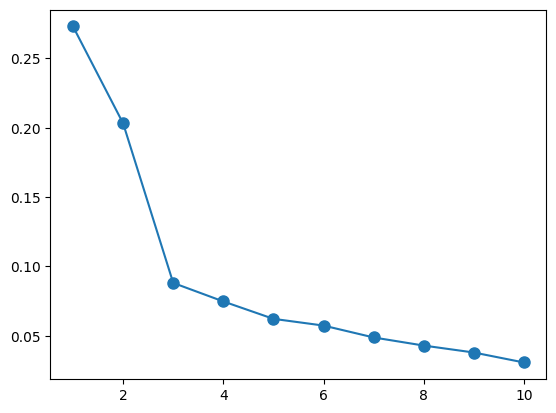

In [22]:
# Plotting the explained variance
plt.plot(range(1, 11) , var, marker = 'o', markersize=8)
plt.show()

What did you understand by Explained Variance

Answer:
Explained Variance tell us how much of the variation present in the original dataset is captured by each principal component. Here n_components=0.9 means that keep enough principal components to retain at least 90% of the original variation.

# K-Means Clustering (Partition-Based Clustering)

K-means clustering is an essential partitioning algorithm used to categorize a dataset into 'k' distinct, non-overlapping clusters. Each data point is assigned to the cluster with the nearest mean or centroid, symbolizing the cluster's center. The primary goal of the algorithm is to minimize the sum of squared distances between data points and their respective cluster centroids.

For an in-depth exploration of K-means clustering, you can refer to this comprehensive article on Analytics Vidhya: [Comprehensive Guide to K-means Clustering](https://www.analyticsvidhya.com/blog/2019/08/comprehensive-guide-k-means-clustering/).

For a deeper understanding of the mathematical underpinnings of K-means clustering, Wikipedia is a valuable resource. You can explore the Wikipedia page on K-means clustering for a detailed description: [K-means Clustering Wikipedia](https://en.wikipedia.org/wiki/K-means_clustering). This will help you grasp the mathematical intricacies of the algorithm and its applications in machine learning.

Here are some more resources to help you understand these concepts in depth:https://www.youtube.com/watch?v=4b5d3muPQmA

2D Visualization


In [23]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from ipywidgets import interact

# Function to perform K-Means and plot clusters
def kmeans_clustering(num_clusters):
    kmeans = KMeans(n_clusters=num_clusters, random_state=42)
    kmeans_labels = kmeans.fit_predict(data_pca)

    plt.figure(figsize=(8,6))
    # Plot the first 2 principal components
    plt.scatter(data_pca[:, 0], data_pca[:, 1], c=kmeans_labels, cmap='viridis', edgecolors='k', alpha=0.7)
    # Plot centroids
    plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
                s=80, c='red', marker='X', label='Centroids')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title(f'K-Means Clustering ({num_clusters} clusters)')
    plt.legend()
    plt.show()

# Interactive widget to choose number of clusters
interact(kmeans_clustering, num_clusters=(1, 10, 1))


interactive(children=(IntSlider(value=5, description='num_clusters', max=10, min=1), Output()), _dom_classes=(…

<function __main__.kmeans_clustering(num_clusters)>

3D Visualization

In [24]:
def kmeans_3d_clustering(num_clusters):
    kmeans_3d = KMeans(n_clusters=num_clusters, random_state=42)
    kmeans_3d_labels = kmeans_3d.fit_predict(data_pca)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(data_pca[:, 0], data_pca[:, 1], data_pca[:, 2], c=kmeans_3d_labels, cmap='viridis', edgecolors='k')
    ax.set_xlabel('Feature 1 (Standardized)')
    ax.set_ylabel('Feature 2 (Standardized)')
    ax.set_zlabel('Feature 3 (Standardized)')
    ax.set_title('Kmeans Clustering (3D)')
    plt.show()

interact(kmeans_3d_clustering, num_clusters=(1, 6, 1))

interactive(children=(IntSlider(value=3, description='num_clusters', max=6, min=1), Output()), _dom_classes=('…

<function __main__.kmeans_3d_clustering(num_clusters)>

# Elbow Point

The "elbow point" is a concept often used in the context of K-means clustering to help determine the optimal number of clusters (k) for a given dataset. It is a graphical method that can assist data analysts and machine learning practitioners in finding an appropriate value for k when applying K-means clustering.

The rationale behind the elbow point method is that as you increase the number of clusters (k), the sum of squared distances will generally decrease because data points will be closer to their respective cluster centroids. However, beyond a certain point, subdividing the data into more clusters doesn't provide significant improvements in reducing the sum of squared distances. The elbow point represents that optimal trade-off between the number of clusters and the compactness of each cluster.

It's important to note that the elbow point method is a heuristic and not a foolproof method for determining the ideal k value. In some cases, the elbow point may not be very pronounced, making it challenging to choose the best k. Additionally, the choice of k should also consider domain knowledge and the specific goals of your analysis.


For a clearer and more intuitive explanation of this topic, you can refer to the following video::https://www.youtube.com/watch?v=5shTLzwAdEc (Jump to timestamp 14:28 for elbow method)

Elbow Method to determine the number of clusters to be formed:


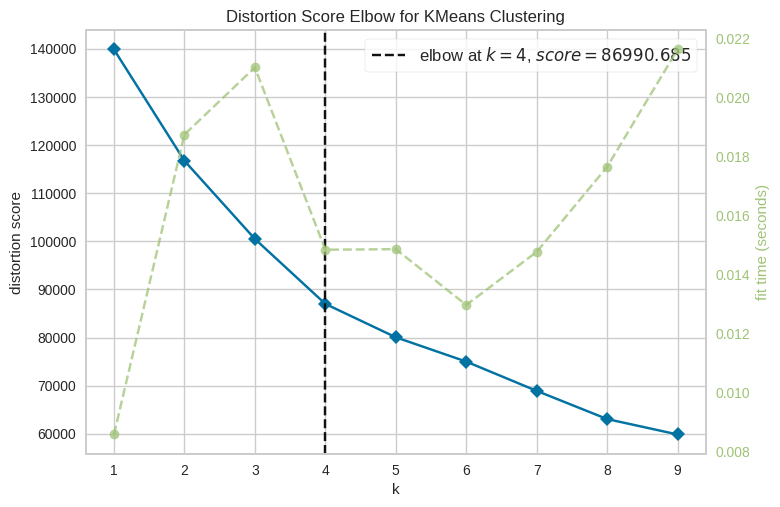

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [25]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans

print('Elbow Method to determine the number of clusters to be formed:')

Elbow_M = KElbowVisualizer(KMeans(random_state=42), k=(1, 10))
Elbow_M.fit(data_pca)
Elbow_M.show()


# Agglomerative Clustering

It is a hierarchical clustering algorithm used in unsupervised machine learning and data analysis. It is a "bottom-up" or "agglomerative" approach to clustering, where individual data points are initially treated as their own clusters and then progressively merged into larger clusters based on a similarity or distance metric. The result is a tree-like structure called a dendrogram that represents the hierarchical relationships between clusters.

As always, You can find more detailed information about hierarchical clustering, including agglomerative clustering, in the Wikipedia article on "Hierarchical clustering" at the following link: [Hierarchical Clustering Wikipedia](https://en.wikipedia.org/wiki/Hierarchical_clustering). This is the best resource for hierarchical clustering and it is advisable to go through it twice if possible! :)

More ref: https://www.analyticsvidhya.com/blog/2019/05/beginners-guide-hierarchical-clustering/

##Exlpain Agglomerative CLustering in your own words:

Answer:
In Agglomerative Clustering at first every data point is considered as an individual cluster unlike K-Means where k centroids are first initialized. Then it repeatedly merges the closest or most similar clusters to form larger clusters.

Similar to classification and regression metrics, we have some [clustering metrics](https://scikit-learn.org/stable/modules/classes.html#clustering-metrics) to evaluate performance.

We wll explore one of them: [silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)

In [26]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Perform Agglomerative Clustering with 3 clusters
agglo = AgglomerativeClustering(n_clusters=3, linkage='average')
labels = agglo.fit_predict(data_pca)  # or use data_pca if you want PCA-reduced data

# Calculate Silhouette Score
silhouette = silhouette_score(data_pca, labels)  # or data_pca
print("Silhouette Score for 3 clusters:", silhouette)


Silhouette Score for 3 clusters: 0.8387829170309258


Explain Silhoutte score

Look into any 2 other metrics and give a brief explanation.

Do it here :)

Silhouette Score: It tells us how similar a data point is to its own assigned cluster as compared to other clusters. It calculates two values:

Cohesion(ai): It calculates average distance of the data point with all the other points in the same cluster. Lower value means tightly packed cluster.

Separation(bi): It calculates the average distance of data point to all the other data points in the nearest cluster.
Silhouette Coefficient = (bi-ai)/max(ai,bi)

Silhouette Score is the mean of the silhouette coefficient of all data points

Davies Bouldin Index: It measures the similarity between each cluster and its ost similar other cluster. Here lower value indicates that the clusters are compact and well separated from each other.

Calinski Harabasz Index: It evaluates clustering based on the separation between clusters compared with the compactness within clusters. A higher value indicates better-defined clusters.

**3 Dimensional Visualization**

Look into what dendrograms are and plot them here.

Ref: https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html

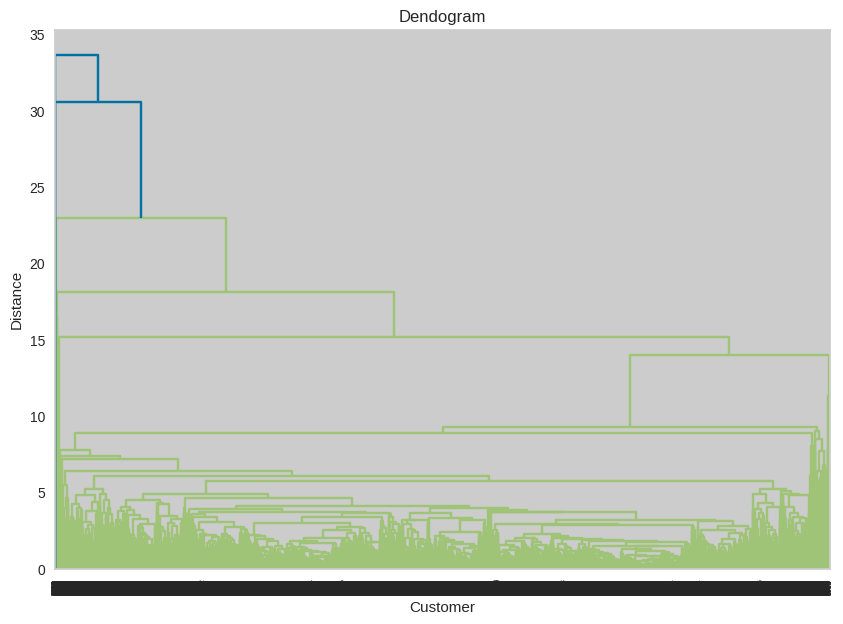

In [33]:
#plot here
from scipy.cluster.hierarchy import dendrogram, linkage

link = linkage(data_pca, method='average')
plt.figure(figsize=(10,7))
dendrogram(link)
plt.title("Dendogram")
plt.xlabel("Customer")
plt.ylabel("Distance")
plt.show()

# DBSCAN Clustering

DBSCAN, which stands for Density-Based Spatial Clustering of Applications with Noise, is a popular density-based clustering algorithm in unsupervised machine learning. It is particularly useful for discovering clusters of arbitrary shapes in datasets with varying levels of data density. DBSCAN is known for its ability to handle noise and outliers effectively.

As always, You can find additional information about how DBSCAN clustering works in the following article on Analytics Vidhya:

[How DBSCAN Clustering Works](https://www.analyticsvidhya.com/blog/2020/09/how-dbscan-clustering-works/#:~:text=DBSCAN%20is%20a%20density%2Dbased,points%20into%20a%20single%20cluster.)

This article provides a detailed explanation of DBSCAN, including its underlying concepts, the role of epsilon (ε) and minimum points (MinPts), and practical examples of how to use DBSCAN for clustering. It's a valuable resource for gaining a deeper understanding of the algorithm with Wikipedia as the side resource.

Take a look at this short video to gain a better understanding of the concept:https://www.youtube.com/watch?v=RDZUdRSDOok

**2 Dimensional Visualization**

In [37]:
# Perform DBSCAN clustering with interactive widget
def dbscan_clustering(eps, min_samples):
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    dbscan_labels = dbscan.fit_predict(data_pca)#code here

    print(np.unique(dbscan_labels, return_counts=True))

    #plot here
    plt.figure(figsize=(8, 6))

    plt.scatter(
      data_pca[:, 0],
      data_pca[:, 1],
      c=dbscan_labels,
      cmap='viridis',
      edgecolors='k',
      alpha=0.7
    )

    plt.xlabel('PC 1')
    plt.ylabel('PC 2')
    plt.title('DBSCAN Clustering')
    plt.show()

# Interactive widget
interact(dbscan_clustering, eps=(0.1, 2.0, 0.1),min_samples=(2, 20, 1)) #fill here


interactive(children=(FloatSlider(value=1.0, description='eps', max=2.0, min=0.1), IntSlider(value=11, descrip…

<function __main__.dbscan_clustering(eps, min_samples)>

**3 Dimensional Visualization**

In [39]:
def dbscan_3d_clustering(eps, min_samples):
    #Write the complete function yourself
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    dbscan_labels= dbscan.fit_predict(data_pca)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(data_pca[:, 0], data_pca[:, 1], data_pca[:, 2], c=dbscan_labels, cmap='viridis', edgecolors='k')
    ax.set_xlabel('PC 1')
    ax.set_ylabel('PC 2')
    ax.set_zlabel('PC 3')
    ax.set_title('DBSCAN Clustering 3D')
    plt.show()

# Interactive widget
interact(dbscan_3d_clustering, eps=(0.1, 2.0, 0.1), min_samples=(2, 20, 1))


interactive(children=(FloatSlider(value=1.0, description='eps', max=2.0, min=0.1), IntSlider(value=11, descrip…

<function __main__.dbscan_3d_clustering(eps, min_samples)>

After performing K-Means and Agglomerative clustering on the dataset, what differences and similarities did you notice between the two methods? What insights did you gain from the cluster patterns?

Answer:

# **Research Task**

In this task, we covered clustering and Dimensionality reduction. But still, one aspect of Unsupervised Learning is left to be covered- **Association rules**. Reseach about this topic and mention the different algos that exist and their real life application.

 Also, look into the functioning of **Spectral Clustering algorithm** and create a word doc


# **End of Task**

> ©DJS Synapse 2026 - 2027